# Week 6 — Seoul Bike: External Cloud Cover Feature

**Team B | Data integration → model extension → controlled evaluation**

**Question:** Does adding one external weather variable (`cloud_cover_pct`) improve our existing **Week 5 hourly linear demand forecast**?

We compare two **retrained** models, on the **same observations** with the **same chronological split**:

- **Original (Week 5):** `D(t+1) = b0 + b1·D(t) + b2·T(t+1) + b3·H(t+1) + g(hour(t+1))`
- **Extended (Week 6):** the same equation **plus** `b4·cloud_cover(t+1)`.

**Important distinctions:** This is an extension of the **Week 5 linear model**, not Week 3's multiplicative model or Week 4's synchronization. Historical weather recorded at `t+1` is treated as a **perfect weather forecast already available at t**, as in Week 5. This is a retrospective experiment, not an operational live forecast. Model fitting never uses next-hour rentals as a predictor.

**Source / provenance:** `SeoulBikeData.csv` (UCI Seoul Bike Sharing Demand; aggregate rentals) and `open-meteo-37.57N126.96E27m.csv` (Open-Meteo Historical Weather, hourly cloud cover, 37.57469°N 126.96°E). The uploaded Open-Meteo file states `timezone=GMT` and must be converted to **Asia/Seoul** before merging. Open-Meteo values describe a nearby weather-model grid point, not necessarily conditions at every rental station.

## 1. Imports and input file paths

Store `SeoulBikeData.csv` in the repository root and the Open-Meteo CSV either alongside this notebook or in the repository root. The notebook supports running from the `Week-6` directory or from the project root.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BIKE_FILE = 'SeoulBikeData.csv'
WEATHER_FILE = 'open-meteo-37.57N126.96E27m.csv'

def find_file(filename):
    for path in (Path(filename), Path('..') / filename, Path('Week-6') / filename):
        if path.exists():
            return path
    raise FileNotFoundError(f'Cannot find {filename}. Check your working directory.')

bike_path = find_file(BIKE_FILE)
weather_path = find_file(WEATHER_FILE)
print('Bike data:', bike_path)
print('Cloud data:', weather_path)

Bike data: ..\SeoulBikeData.csv
Cloud data: ..\open-meteo-37.57N126.96E27m.csv


## 2. Read and validate Seoul Bike observations

The existing data use **Seoul-local** dates and integer hours. We keep local timestamps as timezone-aware values, and preserve the rental counts. Closed-service hours (`Functioning Day = No`) are excluded from prediction pairs.

In [2]:
bike = pd.read_csv(bike_path, encoding='latin1')
required = ['Date', 'Hour', 'Rented Bike Count', 'Temperature(°C)',
            'Humidity(%)', 'Functioning Day']
missing_columns = sorted(set(required) - set(bike.columns))
if missing_columns:
    raise ValueError(f'Missing Seoul columns: {missing_columns}')

bike['timestamp_local'] = (
    pd.to_datetime(bike['Date'], dayfirst=True)
    + pd.to_timedelta(bike['Hour'], unit='h')
).dt.tz_localize('Asia/Seoul')

print('Original bike rows:', len(bike))
print('Missing required cells:', int(bike[required].isna().sum().sum()))
print('Duplicate timestamps:', int(bike['timestamp_local'].duplicated().sum()))

bike = bike.dropna(subset=required + ['timestamp_local']).copy()
bike = bike[
    (bike['Rented Bike Count'] >= 0)
    & bike['Humidity(%)'].between(0, 100)
    & bike['Functioning Day'].isin(['Yes', 'No'])
    & bike['Hour'].between(0, 23)
].copy()
if bike['timestamp_local'].duplicated().any():
    raise ValueError('Duplicate Seoul timestamps: investigate before merging.')
bike = bike.sort_values('timestamp_local').reset_index(drop=True)
print('Valid bike rows:', len(bike))
print('Bike period:', bike['timestamp_local'].min(), 'to', bike['timestamp_local'].max())

Original bike rows: 8760
Missing required cells: 0
Duplicate timestamps: 0
Valid bike rows: 8760
Bike period: 2017-12-01 00:00:00+09:00 to 2018-11-30 23:00:00+09:00


## 3. Read the historical cloud-cover source and fix the timezone

The uploaded CSV starts with **two metadata rows and a blank row**, then `time,cloud_cover (%)`. Its `time` values are labelled **GMT (UTC)**. We convert UTC → `Asia/Seoul` **before** joining. A timezone mistake would shift hourly weather by nine hours.

`cloud_cover (%)` is a percentage of sky cover (0–100). We retain its UTC timestamp too, for provenance.

In [3]:
weather = pd.read_csv(weather_path, skiprows=3)
if not {'time', 'cloud_cover (%)'}.issubset(weather.columns):
    raise ValueError(f'Unexpected Open-Meteo columns: {list(weather.columns)}')

weather['timestamp_utc'] = pd.to_datetime(weather['time'], utc=True, errors='coerce')
weather['timestamp_local'] = weather['timestamp_utc'].dt.tz_convert('Asia/Seoul')
weather['cloud_cover_pct'] = pd.to_numeric(weather['cloud_cover (%)'], errors='coerce')

print('Cloud rows:', len(weather))
print('Missing cloud values:', int(weather['cloud_cover_pct'].isna().sum()))
print('Missing timestamps:', int(weather['timestamp_local'].isna().sum()))
print('Invalid cloud values:', int((~weather['cloud_cover_pct'].between(0, 100) & weather['cloud_cover_pct'].notna()).sum()))

if weather['timestamp_local'].isna().any():
    raise ValueError('Open-Meteo timestamps could not be parsed.')
if weather['timestamp_local'].duplicated().any():
    raise ValueError('Duplicate Open-Meteo timestamps: investigate before merging.')
if (~weather['cloud_cover_pct'].between(0, 100) & weather['cloud_cover_pct'].notna()).any():
    raise ValueError('Cloud cover must be between 0 and 100%.')

weather = weather.sort_values('timestamp_local').reset_index(drop=True)
print('Cloud local period:', weather.timestamp_local.min(), 'to', weather.timestamp_local.max())

Cloud rows: 17520
Missing cloud values: 0
Missing timestamps: 0
Invalid cloud values: 0
Cloud local period: 2017-01-01 09:00:00+09:00 to 2019-01-01 08:00:00+09:00


## 4. Integrate by exact hourly Seoul timestamp

A **left join** preserves all Seoul rental observations, even if a weather value is missing. We do **not** guess or fill missing cloud values. To compare two models fairly, we will later restrict both to identical available rows.

In [5]:
integrated = bike.merge(
    weather[['timestamp_local', 'timestamp_utc', 'cloud_cover_pct']],
    on='timestamp_local', how='left', validate='one_to_one', indicator=True
)

matched = int(integrated['cloud_cover_pct'].notna().sum())
missing_weather = int(integrated['cloud_cover_pct'].isna().sum())
print(f'Weather matches: {matched}/{len(integrated)} ({matched / len(integrated):.1%})')
print('Missing cloud hours:', missing_weather)
print('Join statuses:', integrated['_merge'].value_counts().to_dict())
print('Local timestamp gaps:', int((integrated['timestamp_local'].diff().dropna() != pd.Timedelta(hours=1)).sum()))
print(integrated[['timestamp_local', 'timestamp_utc', 'Rented Bike Count',
                  'Temperature(°C)', 'Humidity(%)', 'cloud_cover_pct']].head(20).to_string(index=False))
assert matched > 0, 'No cloud data matched: check UTC → Asia/Seoul conversion.'
assert integrated['timestamp_local'].is_monotonic_increasing

Weather matches: 8760/8760 (100.0%)
Missing cloud hours: 0
Join statuses: {'both': 8760, 'left_only': 0, 'right_only': 0}
Local timestamp gaps: 0
          timestamp_local             timestamp_utc  Rented Bike Count  Temperature(°C)  Humidity(%)  cloud_cover_pct
2017-12-01 00:00:00+09:00 2017-11-30 15:00:00+00:00                254             -5.2           37                0
2017-12-01 01:00:00+09:00 2017-11-30 16:00:00+00:00                204             -5.5           38                0
2017-12-01 02:00:00+09:00 2017-11-30 17:00:00+00:00                173             -6.0           39                0
2017-12-01 03:00:00+09:00 2017-11-30 18:00:00+00:00                107             -6.2           40                0
2017-12-01 04:00:00+09:00 2017-11-30 19:00:00+00:00                 78             -6.0           36                0
2017-12-01 05:00:00+09:00 2017-11-30 20:00:00+00:00                100             -6.4           37                0
2017-12-01 06:00:00+09:00 20

## 5. Prepare genuine one-hour-ahead forecasting examples

Each example is issued at hour **t** to predict `D(t+1)`. Its predictors are **current observed rentals** `D(t)` and the **assumed available next-hour forecasts** for temperature, humidity and cloud cover, plus next-hour calendar hour.

Only pairs with timestamps exactly one hour apart and an operating bike service at **both** hours are retained. A missing cloud value excludes that example from **both** models, ensuring a same-row comparison. The target `D_next` is NEVER included in the feature matrix.

In [6]:
now = integrated.iloc[:-1].reset_index(drop=True)
nxt = integrated.iloc[1:].reset_index(drop=True)

pairs = pd.DataFrame({
    'Timestamp': nxt['timestamp_local'].to_numpy(),
    'D_current': now['Rented Bike Count'].to_numpy(dtype=float),
    'T_next': nxt['Temperature(°C)'].to_numpy(dtype=float),
    'H_next': nxt['Humidity(%)'].to_numpy(dtype=float),
    'Cloud_next': nxt['cloud_cover_pct'].to_numpy(dtype=float),
    'Hour_next': nxt['Hour'].to_numpy(dtype=int),
    'D_next': nxt['Rented Bike Count'].to_numpy(dtype=float),
})

consecutive = nxt['timestamp_local'].sub(now['timestamp_local']).eq(pd.Timedelta(hours=1))
operating = now['Functioning Day'].eq('Yes') & nxt['Functioning Day'].eq('Yes')
valid_cloud = nxt['cloud_cover_pct'].notna()
valid = consecutive & operating & valid_cloud
print('Potential hour pairs:', len(pairs))
print('Consecutive pairs:', int(consecutive.sum()))
print('Operating consecutive pairs:', int((consecutive & operating).sum()))
print('Final comparable pairs:', int(valid.sum()))
pairs = pairs.loc[valid].reset_index(drop=True)
if len(pairs) < 100:
    raise ValueError('Too few comparable hours after filtering.')
print(pairs.head().to_string(index=False))

Potential hour pairs: 8759
Consecutive pairs: 8759
Operating consecutive pairs: 8452
Final comparable pairs: 8452
                Timestamp  D_current  T_next  H_next  Cloud_next  Hour_next  D_next
2017-12-01 01:00:00+09:00      254.0    -5.5    38.0         0.0          1   204.0
2017-12-01 02:00:00+09:00      204.0    -6.0    39.0         0.0          2   173.0
2017-12-01 03:00:00+09:00      173.0    -6.2    40.0         0.0          3   107.0
2017-12-01 04:00:00+09:00      107.0    -6.0    36.0         0.0          4    78.0
2017-12-01 05:00:00+09:00       78.0    -6.4    37.0         0.0          5   100.0


## 6. Chronological train / tune / test split

Use the **same 70% / 15% / 15% time-ordered partition** for both models. There is no random shuffling, and test rentals are never used for fitting. The **tune** split is diagnostic only; we do not choose features or coefficients based on its scores.

In [7]:
n = len(pairs)
train_end = int(0.70 * n)
tune_end = int(0.85 * n)
train = pairs.iloc[:train_end].copy()
tune = pairs.iloc[train_end:tune_end].copy()
test = pairs.iloc[tune_end:].copy()
assert train.Timestamp.max() < tune.Timestamp.min() < test.Timestamp.min()
for name, data in [('Train', train), ('Tune', tune), ('Test', test)]:
    print(f'{name}: {len(data)} hours | {data.Timestamp.min()} -> {data.Timestamp.max()}')

Train: 5916 hours | 2017-12-01 01:00:00+09:00 -> 2018-08-06 14:00:00+09:00
Tune: 1268 hours | 2018-08-06 15:00:00+09:00 -> 2018-10-03 14:00:00+09:00
Test: 1268 hours | 2018-10-03 15:00:00+09:00 -> 2018-11-30 23:00:00+09:00


## 7. Define the original and expanded **same-family** models

Original (`b0`–`b3`, plus 23 hour indicators) is taken from **Week 5's final notebook**. The extended model adds exactly **one new feature**, `Cloud_next`, with coefficient `b4`. The first four coefficients and hour effects are trained again for both versions on the same training examples.

Hour 00:00 is the reference hour; the 23 dummy features reflect the known daily demand cycle. No cloud-based rule matching or Week 4 synchronization is involved.

In [8]:
def design_matrix(data, include_cloud=False):
    columns = [
        np.ones(len(data)),
        data['D_current'].to_numpy(dtype=float),
        data['T_next'].to_numpy(dtype=float),
        data['H_next'].to_numpy(dtype=float),
    ]
    if include_cloud:
        columns.append(data['Cloud_next'].to_numpy(dtype=float))
    columns.extend((data['Hour_next'].to_numpy() == h).astype(float)
                   for h in range(1, 24))
    return np.column_stack(columns)


def predict(data, coefficients, include_cloud=False):
    # Linear equation is unchanged within each version; clip only for evaluation.
    raw_prediction = design_matrix(data, include_cloud) @ coefficients
    return np.maximum(0.0, raw_prediction)

original_names = ['b0: intercept', 'b1: persistence', 'b2: temperature (bikes/°C)',
                  'b3: humidity (bikes/%RH)'] + [f'hour_{h:02d}' for h in range(1, 24)]
extended_names = original_names[:4] + ['b4: cloud cover (bikes/% point)'] + original_names[4:]
assert len(original_names) == 27 and len(extended_names) == 28

## 8. Calibrate **both** versions using training data only

`np.linalg.lstsq` minimizes the sum of squared training errors (equivalently training RMSE, before nonnegative clipping). The result is a **fixed** set of coefficients; there is **no** fitting on tune or test. We do not compare against deliberately weak initial guesses: both methods are properly calibrated, so the added value of cloud cover is isolated.

In [9]:
y_train = train['D_next'].to_numpy(dtype=float)
X_original = design_matrix(train, include_cloud=False)
X_extended = design_matrix(train, include_cloud=True)

b_original, _, rank_original, _ = np.linalg.lstsq(X_original, y_train, rcond=None)
b_extended, _, rank_extended, _ = np.linalg.lstsq(X_extended, y_train, rcond=None)
if rank_original != X_original.shape[1] or rank_extended != X_extended.shape[1]:
    raise ValueError('Feature matrix rank deficient: cannot uniquely estimate all coefficients.')

coefficients = pd.DataFrame({
    'Term': original_names[:4] + ['b4: cloud cover (bikes/% point)'],
    'Original (no cloud)': [*b_original[:4], np.nan],
    'Extended (+ cloud)': [*b_extended[:5]],
})
print(coefficients.round(4).to_string(index=False))
print(f'Cloud coefficient b4: {b_extended[4]:+.4f} bikes/hour per percentage point')

                           Term  Original (no cloud)  Extended (+ cloud)
                  b0: intercept             -21.3227            -20.7804
                b1: persistence               0.8692              0.8686
     b2: temperature (bikes/°C)               4.3642              4.3934
       b3: humidity (bikes/%RH)              -1.0406             -0.9679
b4: cloud cover (bikes/% point)                  NaN             -0.1012
Cloud coefficient b4: -0.1012 bikes/hour per percentage point


## 9. Evaluate identical train / tune / test hours

MAE and RMSE are computed for both predictions on **exactly the same rows**; lower is better. We also report a **persistence** diagnostic (`D(t+1)=D(t)`) because adding cloud cover is not useful if a simpler benchmark outperforms both. A negative improvement means that the extended model became worse.

In [11]:
def mae(actual, forecast):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(forecast))))


def rmse(actual, forecast):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))

records = []
for split_name, part in [('Train', train), ('Tune', tune), ('Test', test)]:
    observed = part['D_next'].to_numpy(dtype=float)
    candidates = {
        'Original (Week 5)': predict(part, b_original, include_cloud=False),
        'Extended (+ cloud)': predict(part, b_extended, include_cloud=True),
        'Persistence': part['D_current'].to_numpy(dtype=float),
    }
    for model_name, forecast in candidates.items():
        records.append({'Split': split_name, 'Model': model_name, 'Hours': len(part),
                        'MAE': mae(observed, forecast), 'RMSE': rmse(observed, forecast)})
metrics = pd.DataFrame(records)
print(metrics.round(2).to_string(index=False))

base_test = metrics[(metrics.Split == 'Test') & (metrics.Model == 'Original (Week 5)')].iloc[0]
cloud_test = metrics[(metrics.Split == 'Test') & (metrics.Model == 'Extended (+ cloud)')].iloc[0]
print(f'\nTest MAE change (original - cloud): {base_test.MAE - cloud_test.MAE:+.2f} bikes/hour')
print(f'Test MAE relative improvement: {(base_test.MAE - cloud_test.MAE) / base_test.MAE * 100:+.2f}%')
print(f'Test RMSE change (original - cloud): {base_test.RMSE - cloud_test.RMSE:+.2f} bikes/hour')
print('Conclusion:', 'Cloud improved test MAE.' if cloud_test.MAE < base_test.MAE
      else ('Cloud worsened test MAE.' if cloud_test.MAE > base_test.MAE
            else 'Cloud made no difference to test MAE.'))

Split              Model  Hours    MAE   RMSE
Train  Original (Week 5)   5916 125.97 188.57
Train Extended (+ cloud)   5916 126.03 188.54
Train        Persistence   5916 163.76 265.33
 Tune  Original (Week 5)   1268 162.57 225.07
 Tune Extended (+ cloud)   1268 162.56 224.84
 Tune        Persistence   1268 238.96 337.24
 Test  Original (Week 5)   1268 131.43 194.81
 Test Extended (+ cloud)   1268 131.04 194.32
 Test        Persistence   1268 214.89 313.91

Test MAE change (original - cloud): +0.39 bikes/hour
Test MAE relative improvement: +0.30%
Test RMSE change (original - cloud): +0.48 bikes/hour
Conclusion: Cloud improved test MAE.


## 10. Plot observed vs. both forecasts on unseen test hours

Display the first seven days of the unseen test period. Converting to an hourly index introduces `NaN` at any missing timestamps, so Matplotlib does not draw misleading diagonal lines over missing observations or shutdowns.

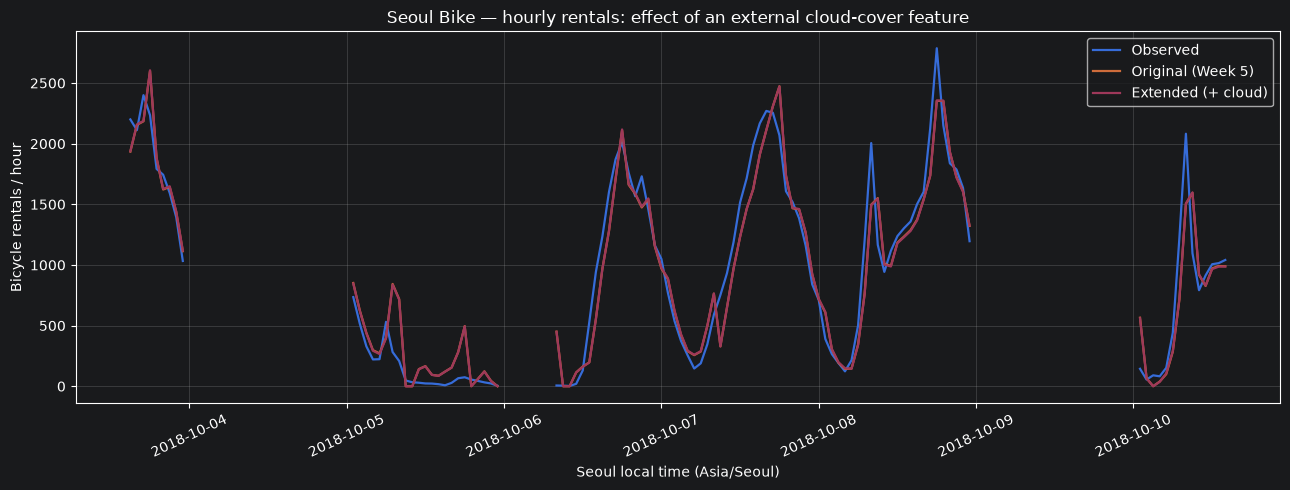

In [12]:
test_results = test[['Timestamp', 'D_next']].rename(columns={'D_next': 'Observed'}).copy()
test_results['Original (Week 5)'] = predict(test, b_original, include_cloud=False)
test_results['Extended (+ cloud)'] = predict(test, b_extended, include_cloud=True)

first_time = test_results['Timestamp'].iloc[0]
chart = test_results[test_results['Timestamp'] < first_time + pd.Timedelta(days=7)]
chart = chart.set_index('Timestamp').asfreq('h')
plt.figure(figsize=(13, 5))
for column in ['Observed', 'Original (Week 5)', 'Extended (+ cloud)']:
    plt.plot(chart.index, chart[column], label=column, linewidth=1.6)
plt.title('Seoul Bike — hourly rentals: effect of an external cloud-cover feature')
plt.xlabel('Seoul local time (Asia/Seoul)')
plt.ylabel('Bicycle rentals / hour')
plt.xticks(rotation=25)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Compare model errors directly (same unseen test hours)

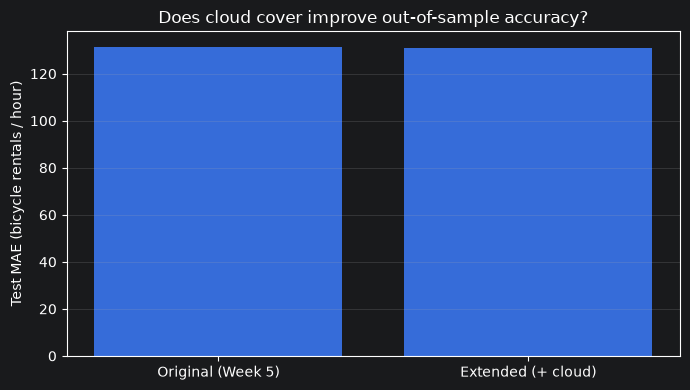

In [13]:
plt.figure(figsize=(7, 4))
plt.bar(['Original (Week 5)', 'Extended (+ cloud)'], [base_test.MAE, cloud_test.MAE])
plt.ylabel('Test MAE (bicycle rentals / hour)')
plt.title('Does cloud cover improve out-of-sample accuracy?')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Interpret the new weather feature and dataset limitations

- **b4 unit:** predicted bicycle rentals **per hour** per **1 percentage point** increase in sky cloud cover, holding current rentals, temperature, humidity, and target hour fixed.
- Positive/negative `b4` is a **conditional association**, not proof of a causal effect. Cloud cover may overlap with the original dataset's solar-radiation measurements and other weather factors.
- More features **do not guarantee better test performance**. Report both the sign/magnitude of `b4` and the test MAE/RMSE even if the effect is small or negative.
- Open-Meteo's historical weather data are retrospective reconstructions; treating the `t+1` observation as an available weather forecast makes this a **perfect-forecast assumption**, not a true real-time evaluation.
- The original Seoul data are city-level hourly rental totals, not station-specific demand. No station-level inference is made.
- We compare **two separately least-squares-calibrated versions**, not an artificially weak initial model; we do not tune parameters using test observations.
- The external weather timestamp must be interpreted in **UTC and converted to Seoul local time**. Any missing cloud rows are excluded from **both** models for fair comparison.

**Model conclusion:** report the actual values printed in Section 9. Improvement, deterioration, or no change are all valid experimental findings if the data pipeline and comparison are correct.